In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
columnas = ["Buying", "Maint", "Doors", "Persons", "Lug_Boot", "Safety", "Class"]
df = pd.read_csv("carEv/car.data", names= columnas, sep=",")
df

,Buying,Maint,Doors,Persons,Lug_Boot,Safety,Class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


In [4]:
orden = {
    "Buying" : ["low", "med", "high", "vhigh"],
    "Maint" : ["low", "med", "high", "vhigh"],
    "Doors" : ["2", "3", "4", "5more"],
    "Persons" : ["2","4","more"],
    "Lug_Boot" : ["small", "med", "big"],
    "Safety" : ["low", "med", "high"],
    "Class" : ["unacc","acc","good","vgood"]
}

for columna, categoria in orden.items():
    df[columna] = pd.Categorical(df[columna],categories=categoria,ordered=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   Buying    1728 non-null   category
 1   Maint     1728 non-null   category
 2   Doors     1728 non-null   category
 3   Persons   1728 non-null   category
 4   Lug_Boot  1728 non-null   category
 5   Safety    1728 non-null   category
 6   Class     1728 non-null   category
dtypes: category(7)
memory usage: 13.1 KB


/tmp/ipykernel_5601/430296123.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=variable, ax=axes[i], palette='viridis')
/tmp/ipykernel_5601/430296123.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=variable, ax=axes[i], palette='viridis')
/tmp/ipykernel_5601/430296123.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=variable, ax=axes[i], palette='viridis')
/tmp/ipykernel_5601/430296123.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.

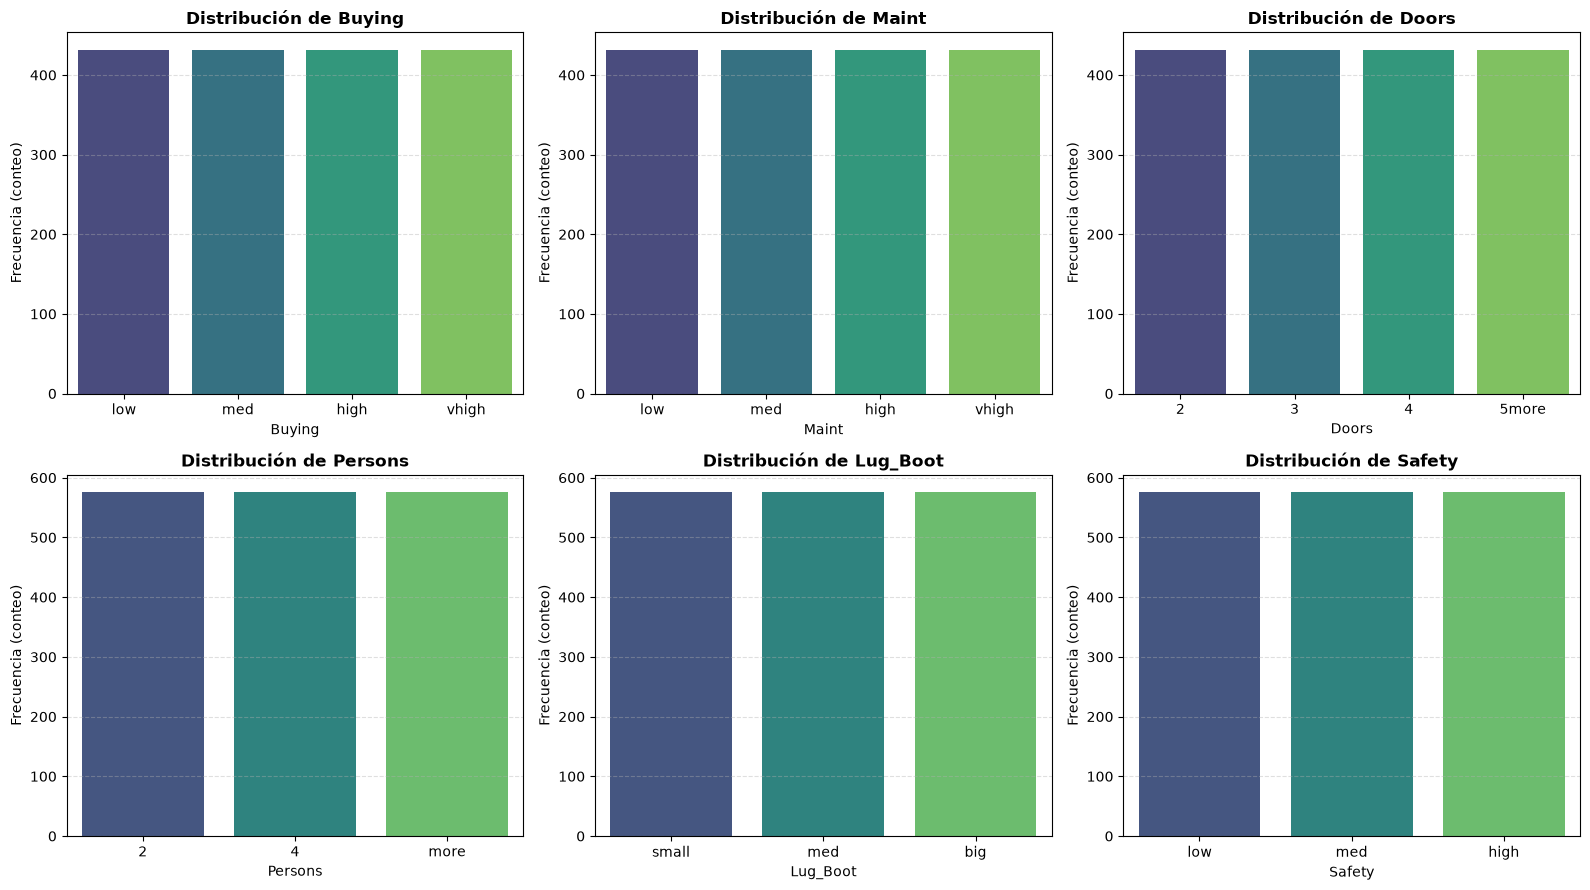

In [6]:
balance = pd.DataFrame({"N" : df["Class"].value_counts(),"%" : (df["Class"].value_counts(normalize=True)*100).round(2)})

balance

comparar = [col for col in df.columns if col != 'Class']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(comparar):
    sns.countplot(data=df, x=variable, ax=axes[i], palette='viridis')
    
    axes[i].set_title(f'Distribución de {variable}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(variable, fontsize=10)
    axes[i].set_ylabel('Frecuencia (conteo)', fontsize=10)
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


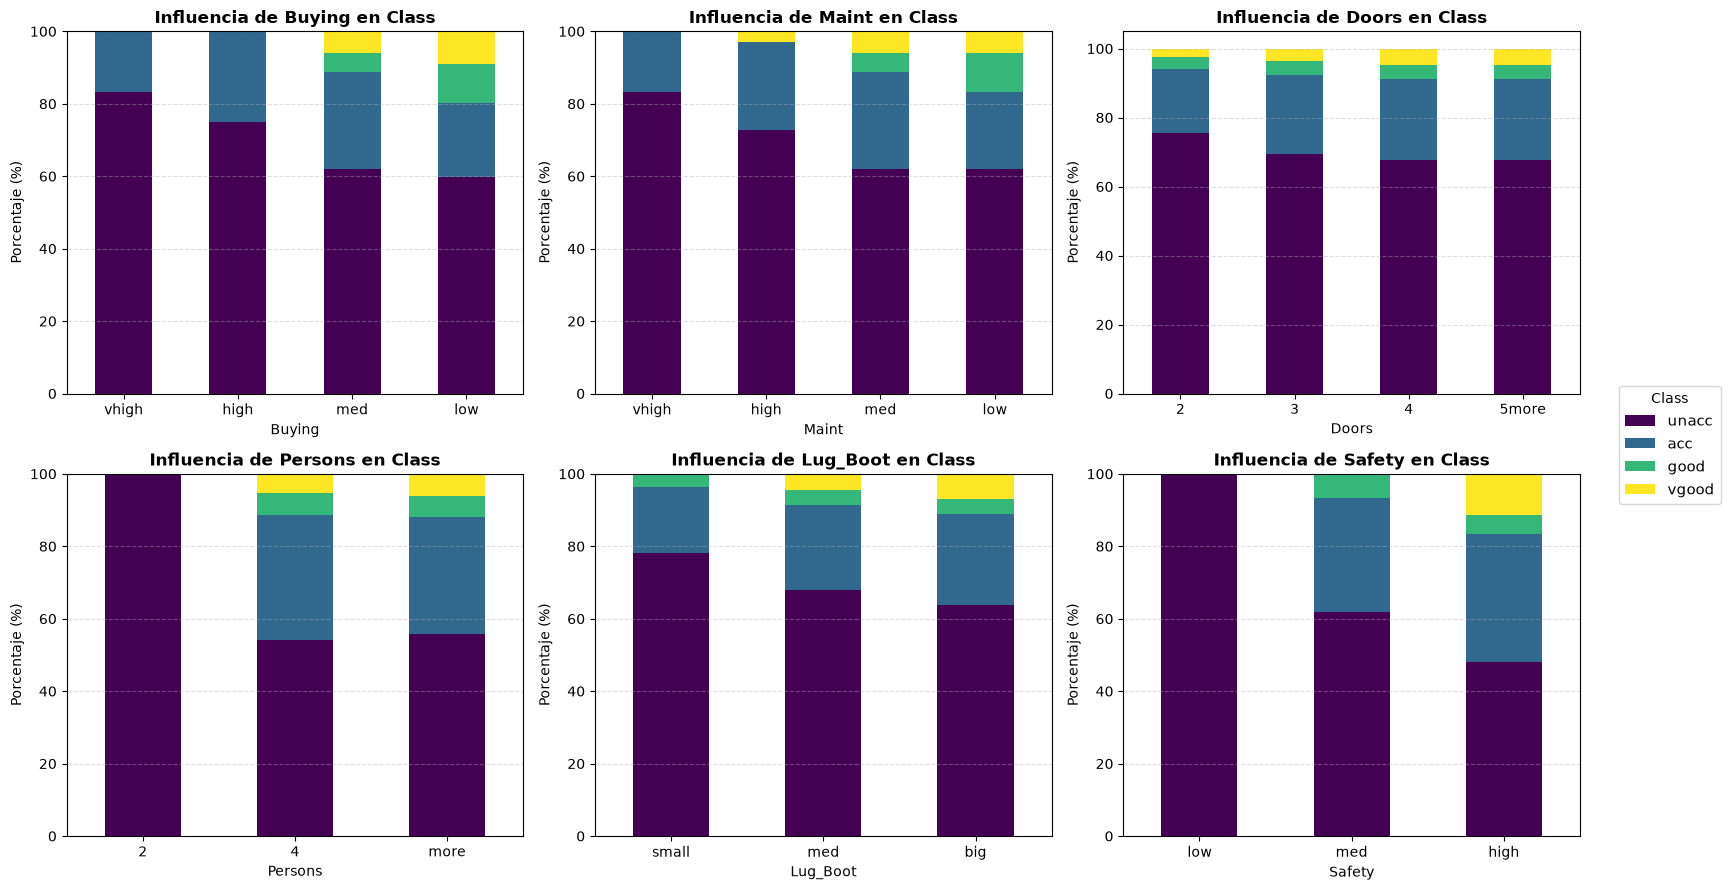

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

for i, variable in enumerate(comparar):
    tabla = pd.crosstab(df[variable], df['Class'], normalize='index') * 100
    
    tabla.plot(kind='bar', stacked=True, ax=axes[i], colormap='viridis', legend=False)
    
    axes[i].set_title(f'Influencia de {variable} en Class', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(variable, fontsize=10)
    axes[i].set_ylabel('Porcentaje (%)', fontsize=10)
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].grid(axis='y', linestyle='--', alpha=0.4)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title='Class', loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=11)

plt.tight_layout()
plt.show()